- 오토인코더는 모든 샘플을 충실하게 인코딩하고 나중에 이를 복수하는 디코딩을 할 수 있다. 이는 특성 추출이나 데이터 표현에는 적합하지만 새로운 샘플을 생성하는데에는 적절하지 않다. 
- 오토 인코더의 latent space는 학습 데이터의 분포를 반영하지 않는 방식으로 구성된다. 데이터에 대응하는 의미있는 latent representation은 생성되나, latent space에서 무작위로 추출한 샘플이 반드시 유효한 이미지로 디코딩 되지는 않는다. 또한 오토인코더의 latent spaces는 불연속적이고 빈공간이 많을 수 있다. 

오토인코더를 확장한 VAE(Variational Autoencoder)는 더 구조화된 latent space를 구성하기 위해 추가제약을 도입한다. 
VAE의 목표는 특정 확률 분포(일반적으로 gaussian distribution)을 따르는 latent space를 만드는 것이다. 이는 단순히 각 입력 샘플을 고정된 latent vector에 매핑하는 것이 아니라 평균과 분산으로 정의되는 확률 분포에 매핑한다. 

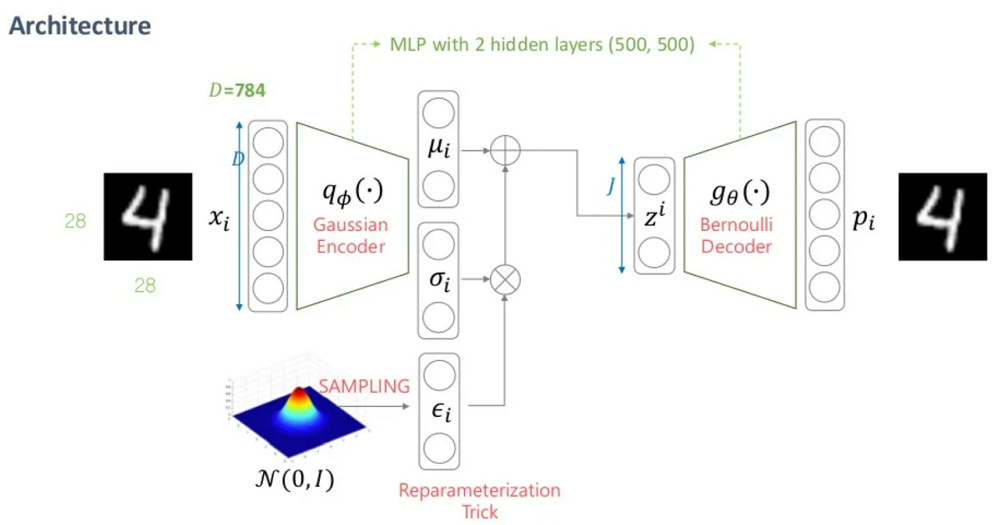

## 1. VAE의 Encoder와 Decoder

VAE의 오토인코더와 디코더는 이전 절의 기본 인코더와 매우 비슷하다. 예시에서는 Convolution layer 몇 개와 선형 층 하나를 사용해 원하는 크기의 latent representation으로 projection(투영, 서로 다른 차원의 벡터를 동일한 차원의 공간으로 변환)했다. 

첫 번째 VAE를 사용할 때에도 동일한 아키텍쳐를 사용하며, 유일한 차이점은 선형 계층을 이미지 latent space를 예측하는데 사용하는 것이 아닌 distribution을 사용하는데 학습한다.
distribution은 평균과 분산이라는 두 가지 매개변수로 특정지어지므로 두 개의 선형 계층이 필요하다. 
- 선형 층 하나는 학습하려는 분포의 평균을 나타낸다.
- 다른 선형 계층은 분포의 분산을 학습한다(그러나 진짜 분산은 아님)

In [1]:
from torch import nn

def conv_block(in_channels, out_channels, kernel_size=4, stride=2, padding=1):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
    )

class VAEEncoder(nn.Module):
    def __init__(self, in_channels, latent_dims):
        super().__init__()
        self.conv_layers = nn.Sequential(
            conv_block(in_channels, 128),
            conv_block(128, 256),
            conv_block(256, 512),
            conv_block(512, 1024),
        )
        self.mu = nn.Linear(1024, latent_dims)
        self.logvar = nn.Linear(1024, latent_dims)
    
    def forward(self, x):
        bs = x.shape[0]
        x = self.conv_layers(x) # (bs, 1024, 1, 1)
        x = x.reshape(bs, -1) # (bs, 1024)
        mu = self.mu(x) # (bs, latent_dims)
        logvar = self.logvar(x) # (bs, latent_dims)
        return (mu, logvar)


디코더의 경우 이전 오토인코더에서와 동일한 임무를 가진다. 즉, latent space의 점 z가 주어지면 인코딩된 representation이 z와 가장 유사한 픽셀을 보여주는 것이다. 
- 일반 AE: z는 합성곱 층에서 추출한 특성을 선형변환한 결과
- VAE: 정규분포의 매개변수(평균과 분산)을 얻은 다음, 그 분포에서 실제값을 추출(샘플링)하여 z를 얻음
따라서 디코더는 그대로 사용할 수 있으나, 분포에서 샘플링하는 부분을 모델에 추가해야한다. 

## 2. Encoder Distribution에서 샘플링하기

수정된 VAE는 입력 데이터 표현과 일치하려는 정규분포의 평균과 분산을 반환한다. 

In [2]:
def conv_transpose_block(in_channels, out_channels, kernel_size=3, stride=2, padding=1, output_padding=0, with_act=True):
    modules = [
        nn.ConvTranspose2d(
            in_channels, 
            out_channels,
            kernel_size=kernel_size, 
            stride=stride, 
            padding=padding, 
            output_padding=output_padding),
    ]
    
    if with_act:
        modules
        modules.append(nn.ReLU())
    return nn.Sequential(*modules)

class Decoder(nn.Module):
    def __init__(self, out_channels, latent_dims):
        super().__init__()

        self.linear = nn.Linear(latent_dims, 1024 * 4 * 4)
        self.t_conv_layers = nn.Sequential(
            conv_transpose_block(1024, 512),
            conv_transpose_block(512, 256, output_padding=1),
            conv_transpose_block(
                256, out_channels, output_padding=1, with_act=False
                ),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        bs = x.shape[0]
        x = self.linear(x)
        x = x.reshape((bs, 1024, 4, 4))
        x = self.t_conv_layers(x)
        x = self.sigmoid(x)
        return x

In [3]:
class VAE(nn.Module):
    def __init__(self, in_channels, latent_dims):
        super().__init__()
        self.encoder = VAEEncoder(in_channels, latent_dims)
        self.decoder = Decoder(in_channels, latent_dims)
    
    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        z = self.sample(mu, std)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar
    
    def sample(self, mu, std):
        eps = torch.randn_like(std)
        return mu + eps * std

1. latent_dims 차원을 사용해 분포의 평균과 로그 분산을 표현한다. 
2. 인코더는 이제 평균과 로그 분산 두 가지 변수를 계산한다.
3. 로그 분산에서 표준편차를 구한다. 
4. 계산된 평균과 표준편차를 사용해 분포에서 샘플링한다. 
5. 디코더는 샘플을 이미지로 변환한다. 
6. 재구성된 이미지뿐만 아니라 평균과 로그 분산도 함께 반환한다. 
7. 재매개변수화 기법(reparamaterization): 표준 정규분포에서 샘플링한 다음 이동 및 스케일 조정한다. 

### Reparamaterization
정규분포의 유용한 특성은 모든 정규 분포가 이동 및 스케일 조정을 통해 평균이 $0$이고 분산이 $1$인 표준 정규 분포로 표현될 수 있다는 것이다. 이는 임의의 정규분포 $N(\mu, \sigma^2)$ 에서 샘플을 얻기 위해 $N(0, 1)$에서 샘플링한 다음 $\sigma$를 곱하고 $\mu$를 더할 수 있음을 의미한다. 이를 재매개변수화라고 표현한다. 

$$
N(\mu, \sigma^2) = \mu + \sigma \cdot N(0, 1)
$$

이는 단순히 편의상 사용하는 것이 아니라 학습의 필수 요소이다. 표현식 'mu + eps * std'를 사용할 때 'eps'는 normal distribution에서 샘플링된 값이다. 모델 입력에 대한 그라디언트는 확률적 과정(분포에서 샘플링)과 독립이기에 계산할 수 있다. 이렇게 하면 신경망을 학습할 때 gradient descent로 모델을 학습시킬 수 있다. 

다차원 정규 분포는 다변량(multivariate)이라고 불린다. 이때 $\mu$는 벡터이고 $\sigma$는 행렬($\Sigma$, covariance matrix)이다. 따라서 분포는 $N(\mu, \Sigma)$로 표기된다. 분포가 모든 차원에서 독립적이라면, 즉 각 변수가 다른 변수랑 상관이 없고 "분산이 동일하다면", 이를 등방성(isotropic)이 있다고 표현한다. isotropic multivariate normal distribution에서 covariance matrix는 diagonal matrix이며 diagonal term의 모든 항목은 동일하고 $\sigma^2 \mathbf{I}$로 표현할 수 있다. 여기서 $\mathbf{I}$는 identity matrix이다. 

안정성 측면에서 살펴보면, 본 모델은 분산 대신 분산의 로그를 예측해 수치적 안정성을 높이고 학습을 용이하게 한다. 실제로 분산은 0에 가까운 양수이다. 그러나 모델이 학습을 시작할 때 모델이 양수이고 작은 값을 생성할 이유는 없다. 또한 부동 소숫점 형식으로 수를 표현하므로 매우 가까운 값들은 구별하기 어렵다. 로그를 취하면 다음과 같은 이점이 있다. 
- 허용가능한 범위가 $-\infty$까지 확장되므로 모델이 부동 소수점값을 사용하여 결과를 더 자유롭게 표현할 수 있다. 
- 'logvar'의 지수함수이기 때문에 분산이 항상 양수임을 보장한다. 

## 3. VAE 학습하기

VAE의 핵심은 손실함수이다. 오토인코더에서는 원본과 재구성한 이미지 간의 차이를 측정한다. VAE는 VAE 제약을 적용하기 위해 손실에 두 번째 요소를 추가한다. 즉, 특성이 대략 정규분포를 따르도록 유도한다. 이 목표는 KL(Kullback-Leibler) Divergeance를 사용해 달성할 수 있다. KL Divergeance는 relative entrophy라고도 하며, 한 distribution이 다른 distribution과 얼마나 다른지를 측정하는 방법이다. multivariate isotrophic normal distribution에서는 KLD를 다음과 같이 계산할 수 있다. 


$$

D_{\mathrm{KL}}\!\left(\mathcal{N}(\mu,\sigma^2)\,\|\,\mathcal{N}(0,1)\right)
= \frac{1}{2}\sum_{i=1}^{d}\left(\mu_i^2+\sigma_i^2-\ln \sigma_i^2-1\right)

$$

이를 위해 코드에서는 다음을 수행한다:
- 디코더가 생성한 픽셀과 원본 이미지 사이의 MSE로 reconstruction loss를 계산한다. 이 loss는 오토인코더 때와 동일하다. 
- 방금 위 식을 따라 KLD 항을 계산한다. 
- 이들을 함께 더한다.  
한 쪽에 더 높은 가중치를 부여해 재구성 충실도와 정규분포 준수 사이의 균형을 맞추어 줄 수도 있다. 

손실 함수는 세 가지 값인 "(1) 총 손실 (2) 재구성 손실 (3) KLD 항"을 반환한다. 


In [4]:
import torch
from matplotlib import pyplot as plt        
from torch.nn import functional as F
from tqdm.notebook import tqdm, trange

def vae_loss(batch, reconstructed, mu, logvar):
    bs = batch.shape[0]

    reconstruction_loss = F.mse_loss(reconstructed.reshape(bs, -1), batch.reshape(bs, -1), reduction="none",).sum(dim=-1)

    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)

    loss = (reconstruction_loss + kl_loss).mean(dim=0)
    
    return (loss, reconstruction_loss, kl_loss)

이제 모델 학습을 시작해볼 수 있다. 

In [8]:
!pip -q install datasets genaibook

from datasets import load_dataset
mnist = load_dataset("ylecun/mnist")

from torchvision import transforms

def mnist_to_tensor(samples):
    t = transforms.ToTensor()
    samples["image"] = [t(image) for image in samples["image"]]
    return samples

mnist=mnist.with_transform(mnist_to_tensor)
mnist["train"]=mnist["train"].shuffle(seed=42)

from torch.utils.data import DataLoader

bs = 64
train_dataloader = DataLoader(mnist["train"]["image"], batch_size=bs)

from genaibook.core import get_device
device = get_device()

In [9]:
def train_vae(model, num_epochs=10, lr=1e-4):
    model = model.to(device)
    losses = {
        "loss": [],
        "reconstruction_loss": [],
        "kl_loss": [],
    }
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, eps=1e-5)
    for _ in (progress := trange(num_epochs, desc="Training")):
        for _, batch in (
            inner :=tqdm(
                enumerate(train_dataloader), total=len(train_dataloader)
            )
        ):
            batch = batch.to(device)
            reconstructed, mu, logvar = model(batch)
            loss, reconstruction_loss, kl_loss = vae_loss(batch, reconstructed, mu, logvar)
            
            inner.set_postfix(loss=f"{loss.cpu().item():.3f}")
            losses["loss"].append(loss.cpu().item())
            losses["reconstruction_loss"].append(reconstruction_loss.mean().cpu().item())
            losses["kl_loss"].append(kl_loss.mean().cpu().item())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        progress.set_postfix(loss=f"{loss.cpu().item():.3f}", lr=f"{lr:.0e}")
    return losses 
vae_model = VAE(in_channels=1, latent_dims=2)
losses = train_vae(vae_model, num_epochs=10, lr=1e-4)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

...

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

결과를 시각화해볼 수 있다. 

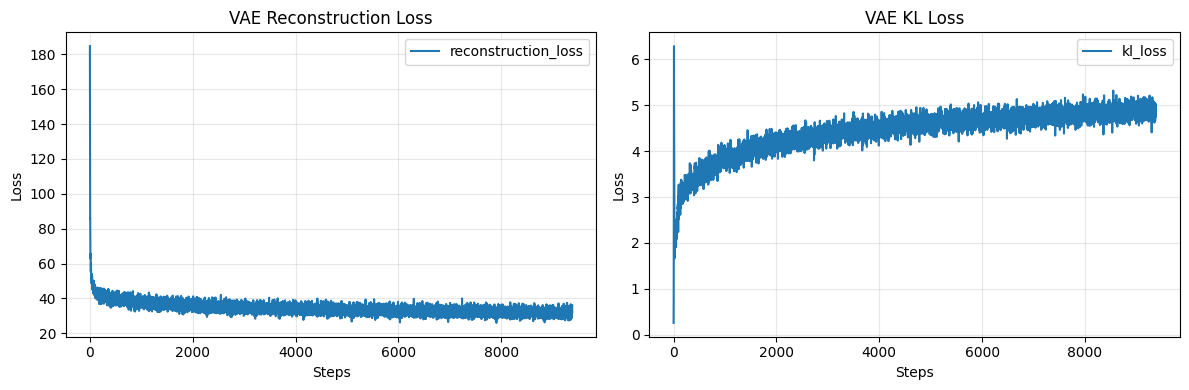

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax_map = {
    "reconstruction_loss": axes[0],
    "kl_loss": axes[1],
}
title_map = {
    "reconstruction_loss": "VAE Reconstruction Loss",
    "kl_loss": "VAE KL Loss",
}

for k, v in losses.items():  # keep this format
    if k in ax_map:
        ax = ax_map[k]
        ax.plot(v, label=k)
        ax.set_title(title_map[k])
        ax.set_xlabel("Steps")
        ax.set_ylabel("Loss")
        ax.legend()
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


위 그래프의 결과를 분석해보면, KL Loss는 초기 학습 시 급등 후 감소하고, 다시 천천히 증가한다. 
1. 학습이 시작될 때 VAE의 인코더와 디코더는 무작위 가중치로 초기화되며, 모델은 입력 데이터를 전혀 알지 못한다. 따라서 출력은 무작위 분포와 비슷하고 KLD는 매우 낮다. 
2. 모델이 데이터의 몇 배치만 보았을 때, 재구성의 질은 낮지만 더는 무작위가 아니며 KLD가 급증한다. 
3. 초기 학습 단계에서 모델은 입력 데이터의 평균 특성 정도는 나타낼 수 있게 된다. KLD 항은 모델이 정규 분포에 점점 더 가까운 출력을 생성할 수 있도록 유도하여 KLD 손실을 낮춘다. 
4. 인코더와 디코더가 더 충실한 표현을 생성하는 법을 배울수록 저육 분포와 일치하면서도 품질을 높이기가 더 어려워진다. 재구성 손실이 지배적이 되고 KLD는 증가하지만 둘 사이의 균형이 있다. 손실 항에서 KLD의 가중치를 높이면 더 나은 정규 분포 일치를 달성할 수 있지만, 그 비용은 더 나쁜 픽셀 표현이 될 것이다. 

VAE의 결과를 시각화 해보자. 

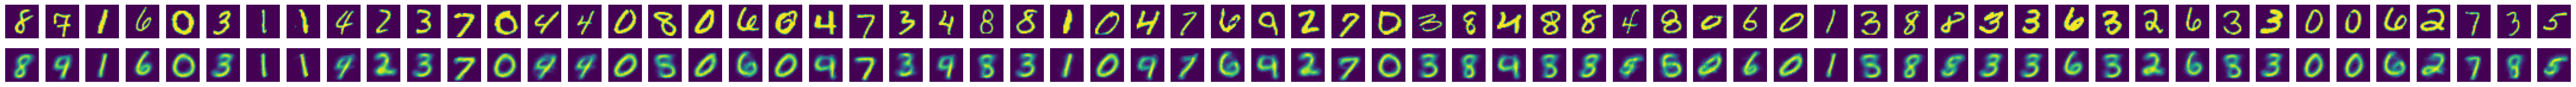

In [11]:
from genaibook.core import show_images

vae_model.eval()
with torch.inference_mode():
    eval_batch = next(iter(train_dataloader))
    predicted, mu, logvar = vae_model(eval_batch.to(device))

batch_vs_preds = torch.cat((eval_batch, predicted.cpu()))
show_images(batch_vs_preds, imsize=1, nrows=2)

시각적인 결과는 오토인코더에서보다 좋지 않다. 이는 모델이 입력 이미지를 인코딩하는 방법을 배울뿐 아니라 정규분포에서 많이 벗어나지 않도록 제약해야하기 때문이다.


하지만, 정규분포에서 순수한 무작위 데이터를 샘플링한 다음 오토인코더행(위쪽)와 VAE 행(아래쪽)의 디코더를 사용해 이로한 점이 어떻게 재구성될지 볼 수 있다. 오토인코더와 VAE는 별도로 학습되었고 각 클래스에 다른 부분의 잠재 공간을 할당했으므로 다른 재구성을 볼 수 있다. 

In [12]:
import torch
from torch import nn

def conv_block(in_channels, out_channels, kernel_size=4, stride=2, padding=1):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
    )

class AEEncoder(nn.Module):
    def __init__(self, in_channels, latent_dims):
        super().__init__()
        self.conv_layers = nn.Sequential(
            conv_block(in_channels, 128),
            conv_block(128, 256),
            conv_block(256, 512),
            conv_block(512, 1024),
        )
        self.linear = nn.Linear(1024, latent_dims)

    def forward(self, x):
        bs = x.shape[0]
        x = self.conv_layers(x)
        x = x.reshape(bs, -1)
        return self.linear(x)

class AutoEncoder(nn.Module):
    def __init__(self, in_channels, latent_dims):
        super().__init__()
        self.encoder = AEEncoder(in_channels, latent_dims)
        self.decoder = Decoder(in_channels, latent_dims)  # 이 노트북의 Decoder 사용

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        return self.decode(self.encode(x))


In [19]:
from pathlib import Path

print(list(Path("/content").rglob("checkpoint_loaders.py")))
print(list(Path("/content").rglob("ae_latent2.pth")))

[]
[Path('/content/chapter03/checkpoints/ae_latent2.pth')]


`checkpoint_loaders.py`를 colab에 업로드한 후 아래의 코드를 실행. 

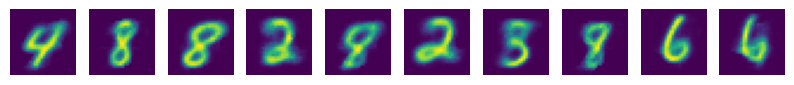

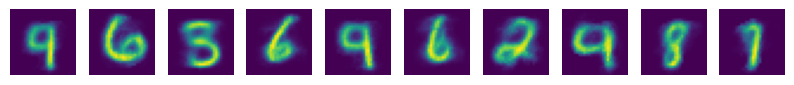

In [20]:
import sys
from pathlib import Path

matches = list(Path("/content").rglob("checkpoint_loaders.py"))
if not matches:
    raise FileNotFoundError("checkpoint_loaders.py를 Colab에 업로드하세요.")

sys.path.insert(0, str(matches[0].parent))
from checkpoint_loaders import load_autoencoder

ae_model = load_autoencoder(
    "/content/chapter03/checkpoints/ae_latent2.pth",
    model_factory=AutoEncoder,
    device=device,
)

z = torch.randn(10, 2, device=device)

ae_model.eval()
vae_model.eval()

with torch.no_grad():
    ae_decoded = ae_model.decode(z)
    vae_decoded = vae_model.decode(z)

show_images(ae_decoded.cpu(), imsize=1, nrows=1)
show_images(vae_decoded.cpu(), imsize=1, nrows=1)

VAE의 결과는 AE에서보다 더 숫자와 비슷하다. 이는 VAE는 학습 과정에서 인코더가 정규분포에서 너무 벗어나지 않도록 권장했지만 AE에서는 그러한 제한이 없었기 때문이다. 

테스트 데이터셋에 대해 모델이 인코딩한 표준 분포의 평균을 그래프로 표시하면 오토인코더에서보다 약간 더 나은 형태를 확인할 수 있다. 결과는 이제 0을 중심으로 더 잘 분포되며 온토인코더에서처럼 멀리 벗어나지 않는다. 클래스들이 차지하는 영역은 크기가 비슷하지만 비슷하게 생긴 숫자 사이에는 여전히 중첩이 있다. 

  0%|          | 0/20 [00:00<?, ?it/s]

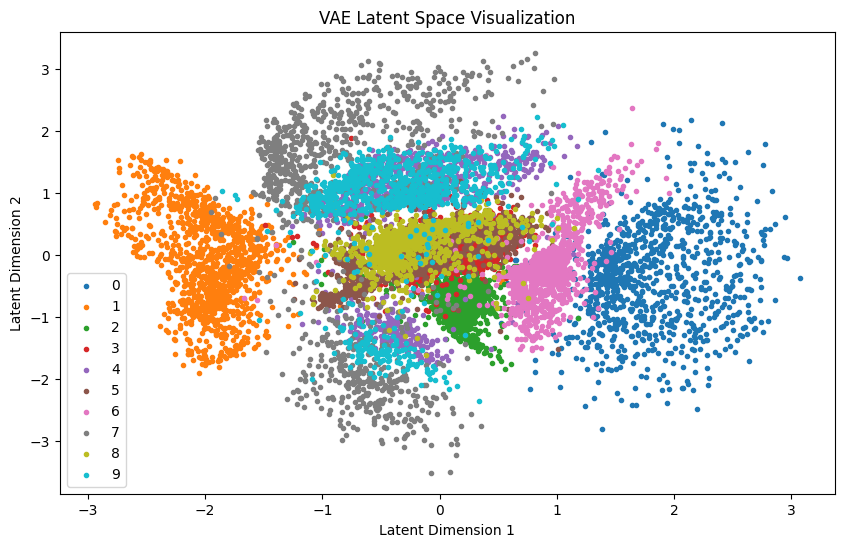

In [21]:
import pandas as pd
images_labels_dataloader = DataLoader(mnist["test"], batch_size=512)

df = pd.DataFrame(
    {
        "x":[],
        "y":[],
        "label":[],
    }
)

for batch in tqdm(
    iter(images_labels_dataloader), total=len(images_labels_dataloader)
):
    mu, _ = vae_model.encode(batch["image"].to(device))
    mu = mu.to("cpu")
    new_items = {
        "x":[t.item() for t in mu[:, 0]],
        "y":[t.item() for t in mu[:, 1]],
        "label": batch["label"],
    }
    df = pd.concat((df, pd.DataFrame(new_items)), ignore_index=True)

plt.figure(figsize=(10, 6))
for label in range(10):
    points = df[df["label"] == label]
    plt.scatter(points["x"], points["y"], label=str(label), marker='.')

plt.legend()
plt.title("VAE Latent Space Visualization")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.show()

점들을 $y \in [-2 , 2] $ 까지 선택하면 재구성이 다양한 숫자를 나타내는 latent space 영역과 일치함을 볼 수 있다. 

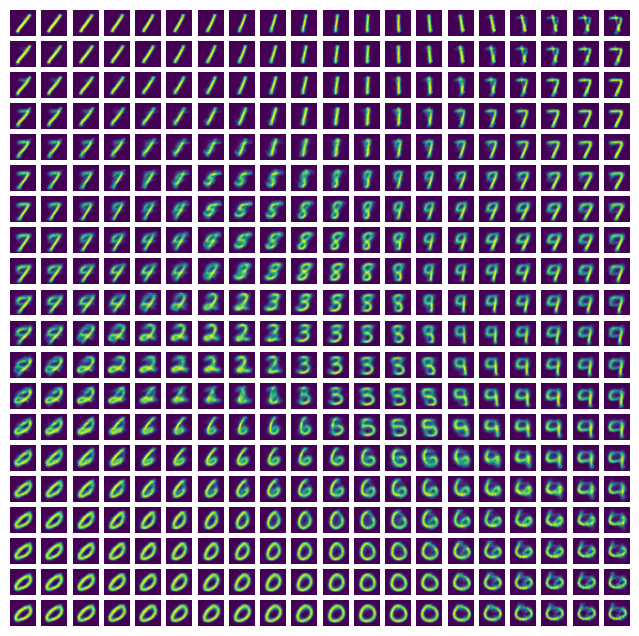

In [22]:
import numpy as np

inputs = []
for x in np.linspace(-2, 2, 20):
    for y in np.linspace(-2, 2, 20):
        inputs.append([x, y])
z = torch.tensor(inputs, dtype=torch.float32).to(device)
decoded = vae_model.to(device).decode(z)
show_images(decoded.cpu(), imsize=0.4, nrows=20)

## 4. 생성 모델링을 위한 VAE

분포에 가까워지도록 제약된 인코더를 학습하는 것은 VAE의 핵심 개념이며 생성 모델링의 기본요소이다. 
- AE를 사용하면 데이터셋의 효율적인 표현을 학습할 수 있으나, 모델이 학습한 latent space가 원본과 유사한 새 데이터를 생성하는데 도움이 된다는 보장이 없었다. 
- VAE를 사용하여 분포 학습을 목표로 삼음ㅇ르ㅗ써, 잠재 공간의 임의의 점에서 시작해 그럴듯한 새 이미지를 생성할 수 있게 해주었다. 
- 확산 모델(diffusion model)은 이 과정에서 반복 개선을 통합하여 무작위 노이즈에서 샘플링하는 이 아이디어를 한 단계 발전시켰다

---

모델 저장

In [24]:
from pathlib import Path

CKPT_DIR = Path("/content/chapter03/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)

vae_ckpt = CKPT_DIR / "vae.pth"

torch.save(
    {
        "model_state_dict": vae_model.state_dict(),
        "in_channels": 1,
        "latent_dims": 2,
    },
    vae_ckpt,
)

print(f"Saved checkpoint: {vae_ckpt}")

Saved checkpoint: /content/chapter03/checkpoints/vae.pth
